In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [ ]:
tickers = [
    'EURUSD=X', 'GBPUSD=X', 'AUDUSD=X', 'NZDUSD=X', 'CADUSD=X',
    'CHFUSD=X', 'JPYUSD=X',  'NOKUSD=X', 'SGDUSD=X',
    'HKDUSD=X', 'ZARUSD=X', 'MXNUSD=X',
     'BTC-USD', 'ETH-USD',
     'BNB-USD', 'SOL-USD', 'ADA-USD', 'XRP-USD', 'DOGE-USD', 'AVAX-USD', 'DOT-USD', 'TRX-USD',
    'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'TSLA', 'NVDA', 'BRK-B', 'JPM', 'UNH',
    'GLD', 'SLV', 'USO', 'UNG', 'DBA'
]

start_date = "2021-01-01"
end_date = "2023-12-31"


In [ ]:

# 2. Download historical data
data = yf.download(tickers, start=start_date, end=end_date)['Close'].pct_change()
data = data.dropna(axis=0)  # Drop assets with missing data
data


[*********************100%***********************]  37 of 37 completed
<ipython-input-194-5afcc7be6a10>:2: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  data = yf.download(tickers, start=start_date, end=end_date)['Close'].pct_change()


Ticker,AAPL,ADA-USD,AMZN,AUDUSD=X,AVAX-USD,BNB-USD,BRK-B,BTC-USD,CADUSD=X,CHFUSD=X,...,SGDUSD=X,SLV,SOL-USD,TRX-USD,TSLA,UNG,UNH,USO,XRP-USD,ZARUSD=X
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-05,0.012364,0.149278,0.010004,0.005752,0.180258,0.019749,-0.004290,0.063197,0.004730,-0.002162,...,0.000107,0.012623,-0.131938,-0.071986,0.007317,0.034921,-0.013448,0.048178,-0.041943,0.004876
2021-01-06,-0.033662,0.284863,-0.024897,-0.012112,0.090372,0.010336,0.012309,0.083311,-0.008480,-0.003382,...,-0.002264,-0.012855,-0.105692,0.065766,0.028390,0.005112,0.041966,0.005009,0.106483,0.018666
2021-01-07,0.034123,-0.096168,0.007577,-0.006656,-0.031111,0.030440,0.011335,0.069157,-0.000519,-0.000198,...,-0.000273,-0.003157,0.229901,0.018122,0.079447,-0.013225,0.016033,0.012313,0.299356,0.005067
2021-01-08,0.008631,0.018725,0.006496,0.005689,0.294977,-0.024262,0.004938,0.036234,0.001396,0.007985,...,0.005218,-0.069279,0.357030,-0.014645,0.078403,0.005155,-0.004493,0.026064,-0.008503,0.026042
2021-01-09,0.000000,0.089582,0.000000,0.000000,0.245195,0.036267,0.000000,-0.013311,0.000000,0.000000,...,0.000000,0.000000,0.051398,0.111489,0.000000,0.000000,0.000000,0.000000,0.011404,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-12-26,-0.002841,-0.027044,-0.000065,-0.003057,-0.081066,0.114650,0.001010,-0.025055,-0.002681,-0.003535,...,-0.000014,0.003617,-0.069913,-0.027036,0.016116,-0.021825,-0.000538,0.022128,-0.037083,0.004449
2023-12-27,0.000518,0.040631,-0.000456,-0.002697,-0.045370,0.087285,0.000336,0.021694,-0.004105,-0.002635,...,-0.001283,0.001351,-0.050170,0.022703,0.018822,0.004057,0.005307,-0.018373,0.020064,0.007546
2023-12-28,0.002226,-0.025434,0.000261,-0.004494,-0.059031,-0.000242,0.001737,-0.018760,0.000555,-0.012972,...,-0.003123,-0.010796,-0.045964,0.001812,-0.031594,0.038384,0.004036,-0.025247,0.000224,-0.013361


In [ ]:
# 3. Calculate daily returns
returns = data.pct_change().dropna()

# 4. Compute correlation matrix
corr_matrix = returns.corr()
corr_matrix
# 5. Calculate average correlation for each asset (excluding self-correlation)
avg_corr = corr_matrix.apply(lambda x: (x.sum() - 1) / (len(x) - 1), axis=1)

# 6. Pick top 10 most correlated assets
top10_assets = avg_corr.sort_values(ascending=False).head(10).index.tolist()
print("Top 10 most correlated assets:")
print(top10_assets)

# 7. (Optional) Slice the original dataset for PCA
selected_data = data[top10_assets]
selected_data

Top 10 most correlated assets:
['GOOGL', 'CHFUSD=X', 'JPYUSD=X', 'ETH-USD', 'TSLA', 'UNG', 'AAPL', 'TRX-USD', 'DOT-USD', 'XRP-USD']


Ticker,GOOGL,CHFUSD=X,JPYUSD=X,ETH-USD,TSLA,UNG,AAPL,TRX-USD,DOT-USD,XRP-USD
Date,,,,,,,,,,
2021-01-05,0.008064,-0.002162,-0.001135,0.057461,0.007317,0.034921,0.012364,-0.071986,0.024504,-0.041943
2021-01-06,-0.009868,-0.003382,-0.004313,0.097369,0.028390,0.005112,-0.033662,0.065766,0.040654,0.106483
2021-01-07,0.029869,-0.000198,0.003400,0.015380,0.079447,-0.013225,0.034123,0.018122,-0.044719,0.299356
2021-01-08,0.013239,0.007985,0.007474,-0.001208,0.078403,0.005155,0.008631,-0.014645,-0.034989,-0.008503
2021-01-09,0.000000,0.000000,0.000000,0.046463,0.000000,0.000000,0.000000,0.111489,0.050567,0.011404
...,...,...,...,...,...,...,...,...,...,...
2023-12-26,0.000212,-0.003535,-0.001565,-0.018084,0.016116,-0.021825,-0.002841,-0.027036,-0.044362,-0.037083
2023-12-27,-0.008126,-0.002635,0.001425,0.065999,0.018822,0.004057,0.000518,0.022703,-0.013174,0.020064
2023-12-28,-0.000997,-0.012972,-0.007354,-0.013105,-0.031594,0.038384,0.002226,0.001812,-0.029065,0.000224


In [ ]:
start_date = '2023-01-01'
end_date = '2025-03-01'
data = yf.download(top10_assets, start=start_date, end=end_date)['Close'].pct_change()
data = data.dropna()

[*********************100%***********************]  10 of 10 completed
<ipython-input-196-2c3c52e69f2c>:3: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  data = yf.download(top10_assets, start=start_date, end=end_date)['Close'].pct_change()


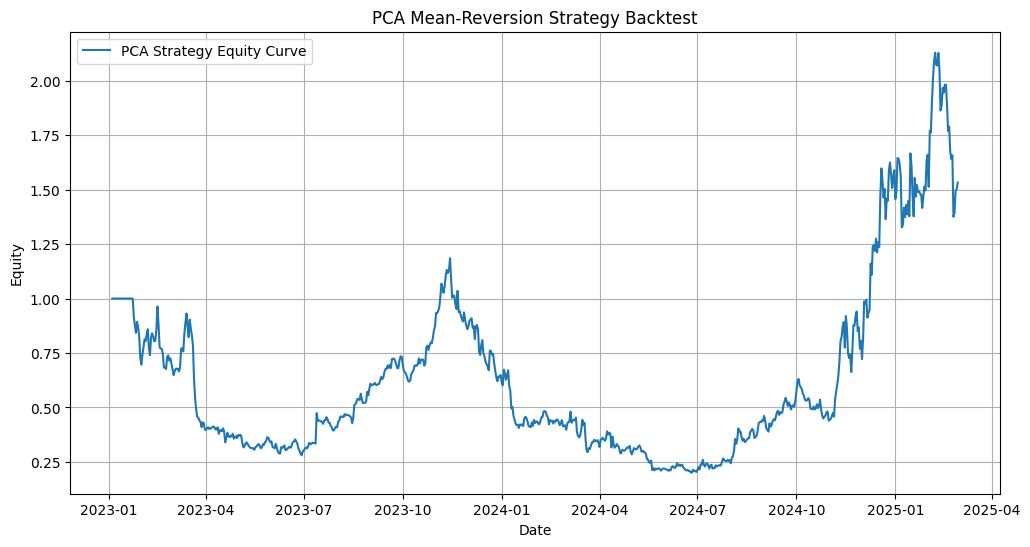

In [ ]:
scaler = StandardScaler()
normalized = scaler.fit_transform(data)
# 3. Apply PCA
pca = PCA()
pca.fit(normalized)
explained_var = pca.explained_variance_ratio_
pc1 = pca.transform(normalized)[:, 0]  # First principal component

# 4. Create signals based on PC1 z-score
pc1_series = pd.Series(pc1, index=data.index)
zscore = (pc1_series - pc1_series.rolling(20).mean()) / pc1_series.rolling(20).std()

# Long if PC1 > -1, Short if PC1 < -1
signals = np.sign(zscore)
signals = pd.Series(signals, index=data.index).fillna(0)

# 5. Construct positions using PC1 loadings (eigenvector)
weights = pd.Series(pca.components_[0], index=data.columns)
positions = signals.to_frame().dot(weights.to_frame().T)  # Daily weights scaled by signal

# 6. Calculate portfolio returns
returns = data
portfolio_returns = (positions.shift(1) * returns).sum(axis=1)

# 7. Calculate equity curve
equity = (1 + portfolio_returns).cumprod()

# 8. Plot results
plt.figure(figsize=(12,6))
plt.plot(equity, label='PCA Strategy Equity Curve')
plt.title('PCA Mean-Reversion Strategy Backtest')
plt.xlabel('Date')
plt.ylabel('Equity')
plt.legend()
plt.grid()
plt.show()

Sharpe Ratio: 0.5786664138953992


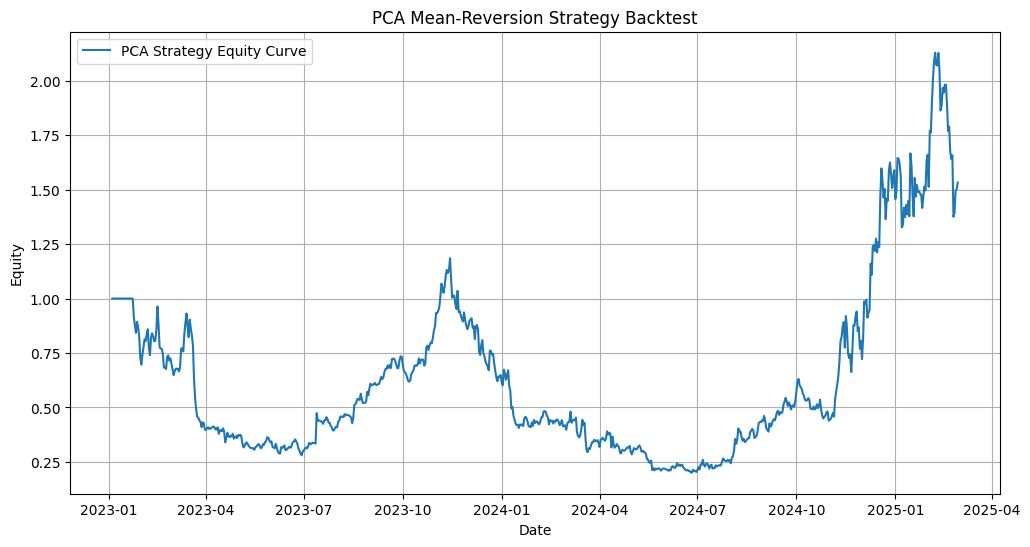

In [ ]:
# prompt: calculate sharpe ratio

import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ... (Your existing code) ...

# Calculate Sharpe Ratio
risk_free_rate = 0.0  # Replace with actual risk-free rate if available
excess_returns = portfolio_returns - risk_free_rate
sharpe_ratio = np.sqrt(252) * excess_returns.mean() / excess_returns.std() # Annualized Sharpe Ratio

print(f"Sharpe Ratio: {sharpe_ratio}")

# 8. Plot results (unchanged)
plt.figure(figsize=(12,6))
plt.plot(equity, label='PCA Strategy Equity Curve')
plt.title('PCA Mean-Reversion Strategy Backtest')
plt.xlabel('Date')
plt.ylabel('Equity')
plt.legend()
plt.grid()
plt.show()
